# A precision platform under floor motion

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/blob/main/laboratories/03-vibration-isolation/notebook.ipynb)

## Goal
An optical platform has mass $m=8\,\mathrm{kg}$ and spring stiffness $k=3200\,\mathrm{N/m}$. Compare damping ratios $\zeta=0.08$ and $0.40$. Derive transmissibility from floor coordinate $z$ to absolute platform coordinate $x$, find the isolation threshold and compare attenuation at $\omega=2\omega_n$. Also find the displacement produced by a static $1\,\mathrm{N}$ force.

**Evidence:** every parameter and dataset is synthetic and was chosen for this original teaching scenario.

## Start from the physical system

![Physical system](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/03-vibration-isolation/figures/physical-system.png)

An optical payload rests on parallel spring and damping elements. The two springs each have stiffness $k/2$, giving total $k$. Both the floor and payload move; spring extension and damping velocity are relative quantities. Weight is balanced at the static equilibrium about which the model is written.

[Five integrated practice problems](https://github.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/blob/main/laboratories/03-vibration-isolation/exercises.pdf) accompany this model.

The equipment view includes state and unit labels, governing balances and interpretation limits. [Vector PDF](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/03-vibration-isolation/figures/physical-system.pdf) · [Editable TikZ](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/03-vibration-isolation/figures/physical-system.tikz).


## Read the system diagram

![System diagram](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/03-vibration-isolation/figures/system-diagram.png)

Base excitation drives absolute motion; subtracting the floor coordinate gives relative travel. The spring and damper act in parallel.

The diagram is original TikZ artwork; the numerical records below are synthetic.

## Setup
Run the optional installation cell if packages are missing. No private data, supplied PDFs or external model files are required.

In [ ]:
%pip -q install numpy scipy matplotlib control

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control as ct
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, least_squares
plt.ioff()
plt.rcParams.update({'figure.figsize': (9,4.5), 'font.size': 10, 'axes.grid': True, 'grid.alpha': .25})


## Derive the model
### Relative forces, absolute displacement
Let $x$ be platform displacement and $z$ floor displacement. The spring and damper act on relative motion:

$$
m\ddot x=-b(\dot x-\dot z)-k(x-z)+f.
$$

Thus the floor and force inputs have different numerators:

$$
\frac{X}{Z}=\frac{bs+k}{ms^2+bs+k},\qquad \frac{X}{F}=\frac1{ms^2+bs+k}.
$$

With $m=8$ kg and $k=3200$ N/m, $\omega_n=20$ rad/s and $b=2\zeta\sqrt{mk}=320\zeta$ N s/m. The two damping values are 25.6 and 128 N s/m.
### Transmissibility and isolation
For $r=\omega/\omega_n$, the squared displacement transmissibility is

$$
|X/Z|^2=\frac{1+(2\zeta r)^2}{(1-r^2)^2+(2\zeta r)^2}.
$$

It is below one precisely when $(1-r^2)^2>1$, or $r>\sqrt2$ for positive frequency. Damping does not move this crossing, but it changes resonance and high-frequency transmission.
### A design tradeoff
At $r=2$, use $\sqrt{[1+16\zeta^2]/[9+16\zeta^2]}$. Greater damping lowers resonance but increases transmission in the isolation band. A static 1 N force produces $x=1/k=0.0003125$ m irrespective of damping.
### Limits
The floor is an imposed displacement, not a second independent mass. Mount stiffness and damping are ideal constants; travel limits, friction, rotations and material nonlinearities are excluded.

## Compute and check
The first lines declare the scenario parameters. Follow the model construction, run the numerical experiment, and inspect the assertions and printed metrics.

In [2]:
mass, stiffness = 8., 3200.
natural=np.sqrt(stiffness/mass)
angular=np.logspace(-1,3,1000)
curves=[]
for damping_ratio in [0.08,0.40]:
    damping=2*damping_ratio*np.sqrt(mass*stiffness)
    model=ct.tf([damping,stiffness],[mass,damping,stiffness])
    response=np.array([abs(ct.evalfr(model,1j*w)) for w in angular])
    crossing=abs(ct.evalfr(model,1j*np.sqrt(2)*natural))
    assert abs(crossing-1)<1e-12
    assert np.all(np.real(ct.poles(model))<0)
    print(f'zeta={damping_ratio:.2f}, b={damping:.3f} N s/m, transmissibility at 2 wn={abs(ct.evalfr(model,2j*natural)):.6f}')
    curves.append((damping_ratio,response))
print(f'Isolation threshold: {np.sqrt(2)*natural:.6f} rad/s; static compliance: {1/stiffness:.8f} m/N')


zeta=0.08, b=25.600 N s/m, transmissibility at 2 wn=0.348010


zeta=0.40, b=128.000 N s/m, transmissibility at 2 wn=0.554940
Isolation threshold: 28.284271 rad/s; static compliance: 0.00031250 m/N


## Plot the evidence
The figure below displays the computed experiment. Axis units and legends distinguish the model variants; the curves are simulations.

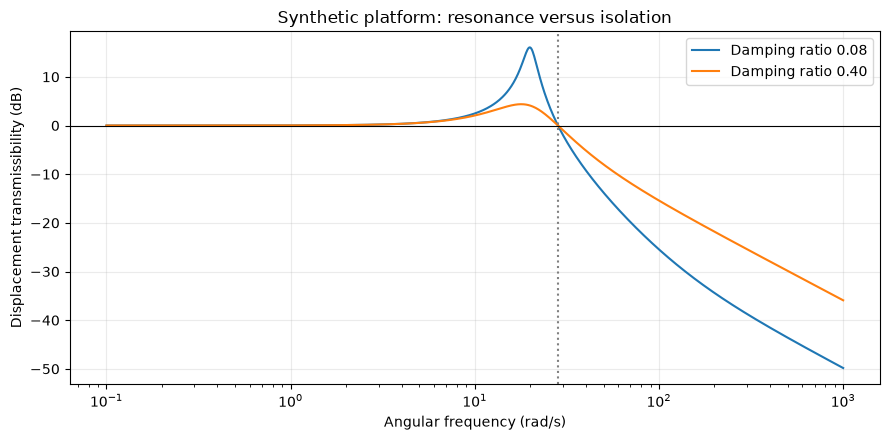

In [3]:
fig,ax=plt.subplots(figsize=(9,4.5))
for ratio,response in curves: ax.semilogx(angular,20*np.log10(response),label=f'Damping ratio {ratio:.2f}')
ax.axhline(0,color='black',lw=.8); ax.axvline(np.sqrt(2)*natural,color='gray',ls=':')
ax.set(xlabel='Angular frequency (rad/s)',ylabel='Displacement transmissibility (dB)',title='Synthetic platform: resonance versus isolation'); ax.legend()
fig.tight_layout()

plt.show()

## Interpret and extend
Reducing a resonance peak and improving high-frequency isolation are different design objectives. The transfer function must reflect which physical input is applied.

Change one parameter at a time, predict the direction of its effect from the equations, and rerun all cells. Explain any discrepancy before accepting a revised conclusion.

## References
- [APMonitor Dynamics and Control](https://apmonitor.com/pdc/)
- [Feedback Systems, open textbook](https://fbsbook.org/)
- [Python Control documentation](https://python-control.readthedocs.io/en/0.10.2/)
- [Worked PDF report](report.pdf)